In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd
import logging
import os
import sys
import shutil
import tempfile

import matplotlib.pyplot as plt
import torch
from torch.utils.tensorboard import SummaryWriter
import numpy as np

import monai
from monai.apps import download_and_extract
from monai.config import print_config
from monai.data import DataLoader, ImageDataset
from monai.transforms import (
    EnsureChannelFirst,
    Compose,
    RandRotate90,
    Resize,
    ScaleIntensity,
)

pin_memory = torch.cuda.is_available()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

logging.basicConfig(stream=sys.stdout, level=logging.INFO)
print_config()
device_id =3

# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/pnxc/Anaconda3/envs/xiaochou/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MONAI version: 0+unknown
Numpy version: 2.2.4
Pytorch version: 2.6.0+cu118
MONAI flags: HAS_EXT = False, USE_COMPILED = False, USE_META_DICT = False
MONAI rev id: 13b96aedc48ad2da16149490b06a1a6bd8361335
MONAI __file__: /home/ssddata/<username>/monai/__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.3.2
scikit-image version: NOT INSTALLED or UNKNOWN VERSION.
scipy version: 1.15.2
Pillow version: 11.1.0
Tensorboard version: 2.19.0
gdown version: NOT INSTALLED or UNKNOWN VERSION.
TorchVision version: 0.21.0+cu118
tqdm version: 4.67.1
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 5.9.0
pandas version: 2.2.3
einops version: 0.8.1
transformers version: 4.40.2
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.

For details about installing the optional dependencies, p

mri和av45配对，或者mri和fdg配对

In [2]:
#mri和av45配对，或者mri和fdg配对
# import os
# import pandas as pd
# import torch
# from transformers import AutoProcessor, AutoModel
# import scipy.io as sio

# # 读取CSV文件并创建Subject到Description和Group的映射
# label_path= "/home/ssddata/liutuo/liutuo_data/filtered_subjects_with_description.csv"
# label = pd.read_csv(label_path)
# label_dict = dict(zip(label["Subject ID"], label["Research Group"]))


# label_desc_dict = dict(zip(label["Subject ID"], label["Description"]))


# # # 使用本地路径加载处理器和模型
# # local_model_path = "/home/ssddata/liutuo/BiomedCLIP"
# # processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
# # model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

# # device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
# # model.to(device)
# # model.eval()

# import nibabel as nib

# # 定义函数以读取 .nii 或 .nii.gz 文件
# def load_nii(file_path):
#     image = nib.load(file_path).get_fdata()  # 获取图像数据
#     return image

# # 获取路径中的数据列表
# def get_data_list_from_path(path):
#     data_list = [os.path.join(path, data) for data in os.listdir(path)]
#     return data_list

# # 获取路径中的数据并创建映射
# def get_data_from_path(path, label_dict):
#     data_all = []
#     for data in os.listdir(path):
#         image = os.path.join(path, data)
#         name = data[:-7]
#         try:
#             label = label_dict[name]
#         except KeyError:
#             continue
#         data_all.append({"image": image, "name": name, "label": label})
#     return data_all

# # 获取配对数据并附加Description
# # 获取配对数据并附加Description，处理 .nii 和 .nii.gz
# def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
#     data_all = []
#     for data in os.listdir(path):
#         if data.endswith(".nii") or data.endswith(".nii.gz"):  # 确保只处理 .nii 或 .nii.gz 文件
#             pet = os.path.join(path, data)
#             name = data[:-7] if data.endswith(".nii.gz") else data[:-4]  # 处理文件名去除扩展名
            
#             print(f"Processing: {name}")  # 打印当前处理的文件名
            
#             try:
#                 mri = mri_name_image_dict[name]
#                 label = label_dict[name]
#                 description = label_desc_dict[name]
#             except KeyError as e:
#                 print(f"KeyError for {name}: {e}")  # 打印没有匹配到的键
#                 continue
            
#             data_all.append({
#                 "pet": pet,
#                 "mri": mri,
#                 "name": name,
#                 "label": label,
#                 "description": description,
#             })
#     return data_all



# import os
# import scipy.io as sio
# # 设置路径
# mri_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_mri"
# fdg_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg_generated"
# av45_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_av45_generated"

# # 获取MRI数据并创建映射
# data_all = get_data_from_path(mri_path, label_dict)

# mri_name_image_dict = dict(zip([data["name"] for data in data_all],
#                                [data["image"] for data in data_all]))


# # 获取配对数据并附加Description
# paired_all_with_desc = get_data_from_path_paired_with_description(av45_path, label_dict, label_desc_dict, mri_name_image_dict)


# # 合并两个数据集
# paired_all_with_desc = paired_all_with_desc
# paired_all_with_desc = [data for data in paired_all_with_desc if data["label"] in ["EMCI","LMCI","CN"]]
# print(paired_all_with_desc)


In [3]:
import os
import pandas as pd
import nibabel as nib

# 读取CSV文件并创建Subject到Description和Group的映射
label_path = "/home/ssddata/liutuo/liutuo_data/filtered_subjects_with_description.csv"
label = pd.read_csv(label_path)
label_dict = dict(zip(label["Subject ID"], label["Research Group"]))
label_desc_dict = dict(zip(label["Subject ID"], label["Description"]))

# 定义函数以读取 .nii 或 .nii.gz 文件
def load_nii(file_path):
    image = nib.load(file_path).get_fdata()  # 获取图像数据
    return image

# 获取路径中的数据列表
def get_data_list_from_path(path):
    data_list = [os.path.join(path, data) for data in os.listdir(path)]
    return data_list

# 获取路径中的数据并创建映射
def get_data_from_path(path, label_dict):
    data_all = []
    for data in os.listdir(path):
        if data.endswith(".nii") or data.endswith(".nii.gz"):  # 确保只处理 .nii 或 .nii.gz 文件
            image_path = os.path.join(path, data)
            name = data[:-7] if data.endswith(".nii.gz") else data[:-4]  # 处理文件名去除扩展名
            print(f"Processing: {name}")  # 打印当前处理的文件名
            try:
                label = label_dict[name]
            except KeyError:
                continue
            
            data_all.append({"image": image_path, "name": name, "label": label})
    return data_all

# 获取配对数据并附加Description
def get_paired_data(mri_dict, fdg_dict, av45_dict, label_dict, label_desc_dict):
    paired_all_with_desc = []
    for name in mri_dict.keys():
        if name in fdg_dict and name in av45_dict:
            try:
                label = label_dict[name]
                description = label_desc_dict[name]
                
                paired_all_with_desc.append({
                    "mri": mri_dict[name],
                    "fdg": fdg_dict[name],
                    "av45": av45_dict[name],
                    "name": name,
                    "label": label,
                    "description": description,
                })
            except KeyError as e:
                print(f"KeyError for {name}: {e}")
                continue
    return paired_all_with_desc

# 设置路径
mri_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_mri"
fdg_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg"
av45_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_av45"

# 获取MRI、FDG、AV45数据并创建映射
mri_data = get_data_from_path(mri_path, label_dict)
fdg_data = get_data_from_path(fdg_path, label_dict)
av45_data = get_data_from_path(av45_path, label_dict)

# 将数据转换为字典形式，方便后续配对
mri_name_image_dict = {data["name"]: data["image"] for data in mri_data}
fdg_name_image_dict = {data["name"]: data["image"] for data in fdg_data}
av45_name_image_dict = {data["name"]: data["image"] for data in av45_data}

# 获取配对数据并附加Description
paired_all_with_desc = get_paired_data(
    mri_name_image_dict,
    fdg_name_image_dict,
    av45_name_image_dict,
    label_dict,
    label_desc_dict
)

# 合并两个数据集并过滤标签
paired_all_with_desc = [
    data for data in paired_all_with_desc if data["label"] in ["EMCI", "LMCI", "CN"]
]

# 打印结果
print(paired_all_with_desc)

Processing: 389_S_10127
Processing: 024_S_1393
Processing: 021_S_6910
Processing: 129_S_1204
Processing: 052_S_4626
Processing: 023_S_0376
Processing: 003_S_7010
Processing: 010_S_0419
Processing: 024_S_4169
Processing: 032_S_4277
Processing: 100_S_0743
Processing: 099_S_4022
Processing: 053_S_5208
Processing: 036_S_4491
Processing: 007_S_4911
Processing: 036_S_4740
Processing: 005_S_0610
Processing: 099_S_4202
Processing: 305_S_6877
Processing: 116_S_6133
Processing: 035_S_6160
Processing: 128_S_0258
Processing: 006_S_6689
Processing: 129_S_4396
Processing: 126_S_2407
Processing: 099_S_6025
Processing: 051_S_6761
Processing: 011_S_6465
Processing: 027_S_1045
Processing: 068_S_2187
Processing: 057_S_1265
Processing: 021_S_5099
Processing: 094_S_2216
Processing: 135_S_4954
Processing: 099_S_4565
Processing: 068_S_2248
Processing: 137_S_4299
Processing: 068_S_4968
Processing: 012_S_4026
Processing: 389_S_10140
Processing: 109_S_4499
Processing: 009_S_4543
Processing: 032_S_0479
Processin

In [4]:
print(len(paired_all_with_desc))

741


In [5]:
import os
import pandas as pd

# 读取CSV文件并创建Subject到Description和Group的映射
label_path = "/home/ssddata/liutuo/liutuo_data/filtered_subjects_with_description.csv"
label = pd.read_csv(label_path)
label_dict = dict(zip(label["Subject ID"], label["Research Group"]))
label_desc_dict = dict(zip(label["Subject ID"], label["Description"]))

# 定义函数以读取 .nii 或 .nii.gz 文件的路径
def get_data_list_from_path(path):
    data_list = [os.path.join(path, data) for data in os.listdir(path) if data.endswith(".nii") or data.endswith(".nii.gz")]
    return data_list

# 获取路径中的数据并创建映射
def get_data_from_path(path, label_dict):
    data_all = []
    for data in os.listdir(path):
        if data.endswith(".nii") or data.endswith(".nii.gz"):  # 确保只处理 .nii 或 .nii.gz 文件
            image_path = os.path.join(path, data)
            name = data[:-7] if data.endswith(".nii.gz") else data[:-4]  # 处理文件名去除扩展名
            
            try:
                label = label_dict[name]
            except KeyError:
                continue
            
            data_all.append({"image": image_path, "name": name, "label": label})
    return data_all

# 获取配对数据并附加Description
def get_paired_data(mri_dict, fdg_dict, av45_dict, label_dict, label_desc_dict):
    paired_all_with_desc = []
    for i, name in enumerate(mri_dict.keys()):
        if name in fdg_dict and name in av45_dict:
            try:
                mri = mri_dict[name]
                fdg = fdg_dict[name]
                av45 = av45_dict[name]
                label = label_dict[name]
                description = label_desc_dict[name]
                
                paired_all_with_desc.append({
                    "mri": mri,
                    "fdg": fdg,
                    "av45": av45,
                    "name": name,
                    "label": label,
                    "description": description,
                    "mri_index": i,
                    "fdg_index": i,
                    "av45_index": i,
                })
            except KeyError:
                continue
    return paired_all_with_desc

# 设置路径
mri_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_mri"
fdg_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg"
av45_path = "/home/ssddata/liutuo/liutuo_data/data_augmentation_av45"

# 获取MRI、FDG、AV45数据并创建映射
mri_data = get_data_from_path(mri_path, label_dict)
fdg_data = get_data_from_path(fdg_path, label_dict)
av45_data = get_data_from_path(av45_path, label_dict)

# 将数据转换为字典形式，方便后续配对
mri_name_image_dict = {data["name"]: data["image"] for data in mri_data}
fdg_name_image_dict = {data["name"]: data["image"] for data in fdg_data}
av45_name_image_dict = {data["name"]: data["image"] for data in av45_data}

# 获取配对数据并附加Description
paired_all_with_desc = get_paired_data(
    mri_name_image_dict,
    fdg_name_image_dict,
    av45_name_image_dict,
    label_dict,
    label_desc_dict
)

# 过滤掉label不是EMCI、LMCI或CN的样本
paired_all_with_desc = [
    data for data in paired_all_with_desc if data["label"] in ["EMCI", "LMCI", "CN"]
]

# 修改标签值：EMCI/LMCI -> 1, CN -> 0
for data in paired_all_with_desc:
    if data["label"] in ["EMCI", "LMCI"]:
        data["label"] = 1
    elif data["label"] == "CN":
        data["label"] = 0

# 给每个样本重新编号
for new_index, data in enumerate(paired_all_with_desc):
    data['index'] = new_index

# 输出检查
print("Keys:", paired_all_with_desc[0].keys())  # 检查新的key是否成功加入
print("Values:", list(paired_all_with_desc[0].values())) 
print("Total Samples:", len(paired_all_with_desc))

Keys: dict_keys(['mri', 'fdg', 'av45', 'name', 'label', 'description', 'mri_index', 'fdg_index', 'av45_index', 'index'])
Values: ['/home/ssddata/liutuo/liutuo_data/data_augmentation_mri/052_S_4626.nii.gz', '/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg/052_S_4626.nii.gz', '/home/ssddata/liutuo/liutuo_data/data_augmentation_av45/052_S_4626.nii.gz', '052_S_4626', 1, 'Subject is a 69-year-old male with a weight of 81.7 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 25. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 3. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 10. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total

In [6]:
import random

# 先打乱 paired_all_with_desc 列表
random.shuffle(paired_all_with_desc)

# 然后为每个数据项赋予编号
for new_index, data in enumerate(paired_all_with_desc):
    data['mri_index'] = new_index
    data['pet_index'] = new_index


In [7]:
positive_samples = [data for data in paired_all_with_desc if data["label"] == 1]
negative_samples = [data for data in paired_all_with_desc if data["label"] == 0]
print(len(positive_samples))
print(len(negative_samples))

436
305


In [8]:
from sklearn.model_selection import StratifiedKFold

# 假设 labels 是每个样本的标签（0 表示 CN，1 表示 AD）
labels = [1] * len(positive_samples) + [0] * len(negative_samples)

# 初始化 StratifiedKFold 对象
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
all_samples=positive_samples+negative_samples
# 使用 StratifiedKFold 进行三折交叉验证
for fold_idx, (train_indices, val_indices) in enumerate(skf.split(all_samples, labels)):
    # 获取训练集和验证集
    train_data = [all_samples[i] for i in train_indices]
    val_data = [all_samples[i] for i in val_indices]

    # 输出当前折的划分信息
    print(f"Fold {fold_idx + 1}:")
    print(f"  训练集大小: {len(train_data)}")
    print(f"  验证集大小: {len(val_data)}")

Fold 1:
  训练集大小: 494
  验证集大小: 247
Fold 2:
  训练集大小: 494
  验证集大小: 247
Fold 3:
  训练集大小: 494
  验证集大小: 247


In [9]:
print(val_data)

[{'mri': '/home/ssddata/liutuo/liutuo_data/data_augmentation_mri/027_S_4955.nii.gz', 'fdg': '/home/ssddata/liutuo/liutuo_data/data_augmentation_fdg/027_S_4955.nii.gz', 'av45': '/home/ssddata/liutuo/liutuo_data/data_augmentation_av45/027_S_4955.nii.gz', 'name': '027_S_4955', 'label': 1, 'description': 'Subject is a 72-year-old male with a weight of 77.1 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 0.5. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 25. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 3. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 7. The Neuropsychiatric Inventory Questionnaire (NPI-Q) Total Score, assessing neuropsychiatric symptom burden (0: no symptoms to higher

In [10]:
from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
train_transforms=mt.Compose([
    mt.LoadImaged(keys=["mri","av45","fdg"]),  # 处理 PET 的 .nii 文件

    mt.EnsureChannelFirstd(keys=["mri","av45","fdg"],channel_dim='no_channel'),
    # mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    # mt.CropForegroundd(keys=["mri"],source_key="mri"),
    
    # mt.HistogramNormalized(keys=["mri"]),
    # mt.ResizeWithPadOrCropd(keys=["mri"],spatial_size=(160,192,160)),
    # mt.Spacingd(keys=["mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    # mt.NormalizeIntensityd(keys=["mri"]),
    # mt.ScaleIntensityd(keys=["mri"],minv=0,maxv=1),
    mt.Identityd(keys=["label"]),
])
val_transforms=mt.Compose([
    mt.LoadImaged(keys=["mri","av45","fdg"]),  # 处理 PET 的 .nii 文件

    mt.EnsureChannelFirstd(keys=["mri","av45","fdg"],channel_dim='no_channel'),
    # mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    # mt.CropForegroundd(keys=["mri"],source_key="mri"),
    
    # mt.HistogramNormalized(keys=["mri"]),
    # mt.ResizeWithPadOrCropd(keys=["mri"],spatial_size=(160,192,160)),
    # mt.Spacingd(keys=["mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    # mt.NormalizeIntensityd(keys=["mri"]),
    # mt.ScaleIntensityd(keys=["mri"],minv=0,maxv=1),
    mt.Identityd(keys=["label"]),
])
train_ds = CacheDataset(data=train_data, transform=train_transforms,num_workers=20)
train_loader = DataLoader(train_ds, batch_size=5, shuffle=True, num_workers=0)    

val_ds = CacheDataset(data=val_data, transform=val_transforms,num_workers=20)
val_loader = DataLoader(val_ds,  batch_size=5,shuffle=False, num_workers=0)

Loading dataset: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 247/247 [01:04<00:00,  3.85it/s]


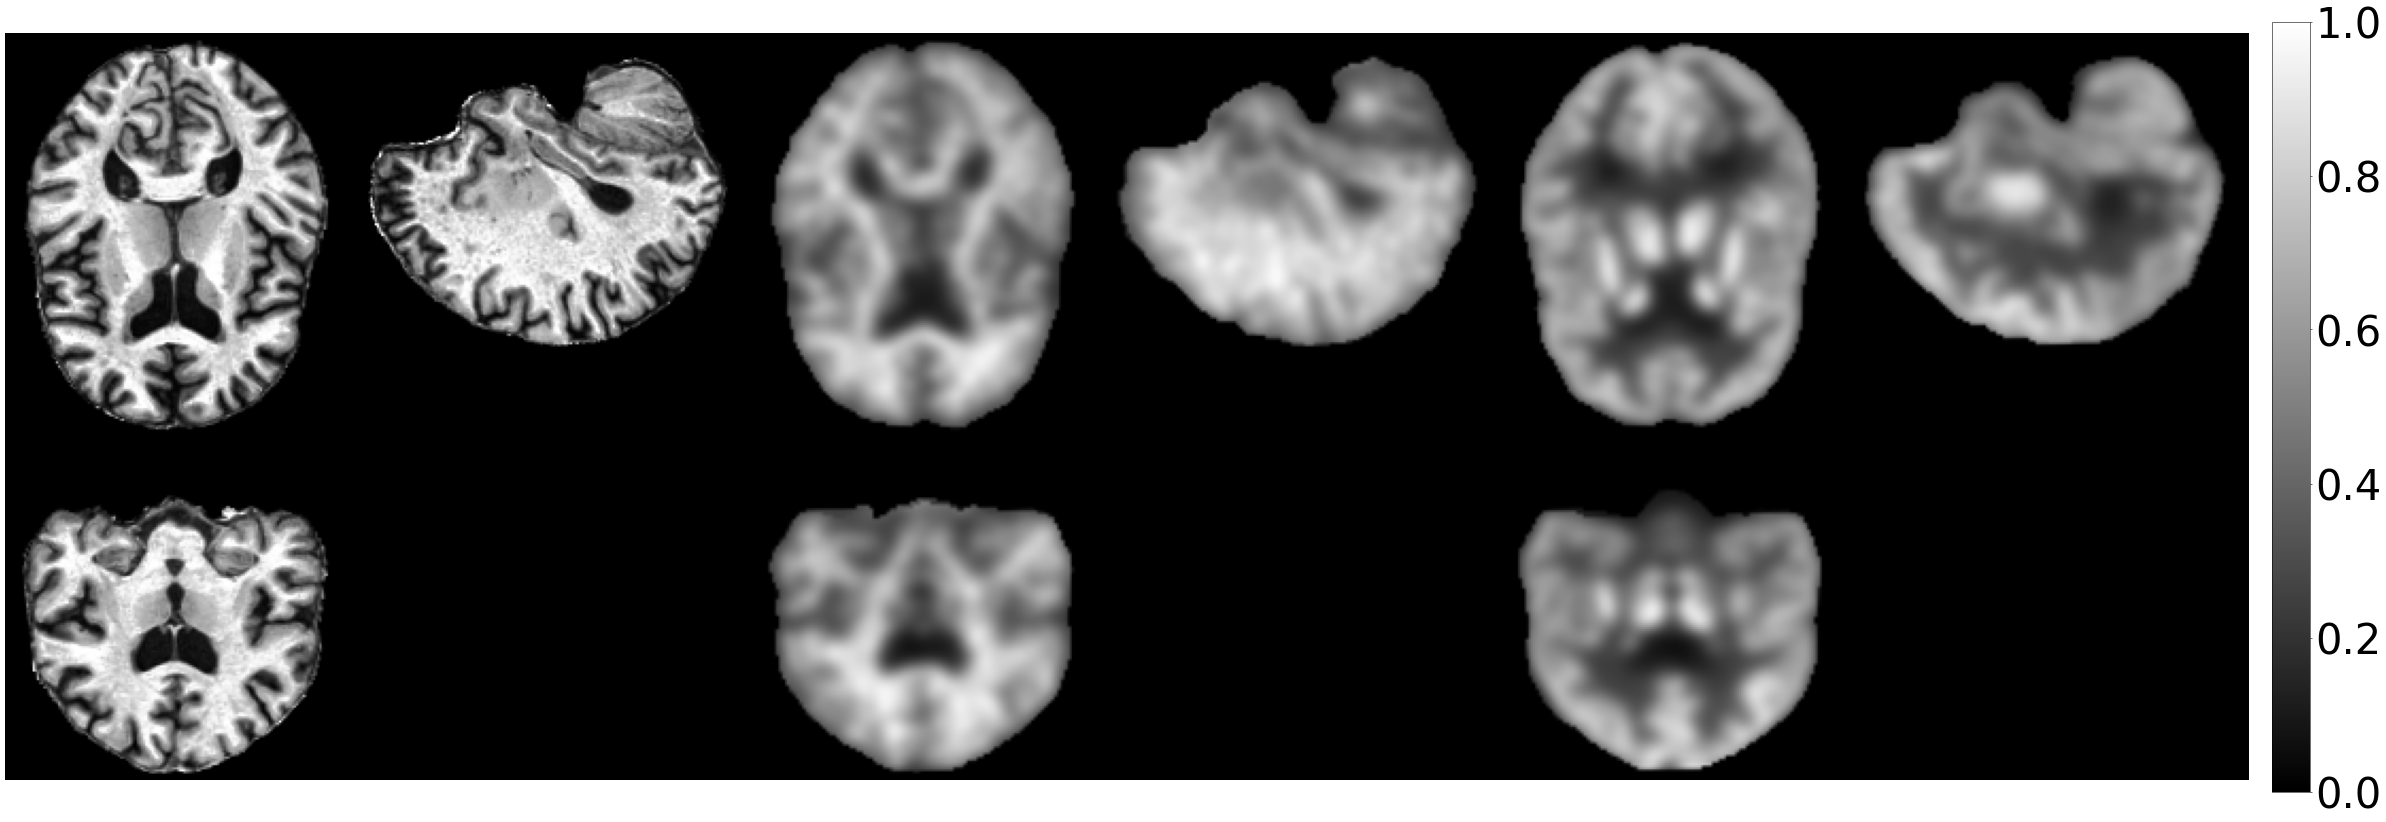

Subject name: 027_S_4955, Label: [0, 1]
Subject name: 094_S_2367, Label: [0, 1]
Subject name: 019_S_4285, Label: [0, 1]
Subject name: 135_S_4309, Label: [0, 1]
Subject name: 014_S_2185, Label: [0, 1]


In [11]:
for batch in val_loader:
    image_1 = batch["mri"]
    label_1 = batch["av45"]
    label_2 = batch["fdg"]
    names = batch["name"]
    labels = batch["label"]
    compare_3d([image_1,label_1,label_2])

    # 将整数标签转换为 one-hot 编码格式
    one_hot_labels = []
    for label in labels:
        if label.item() == 0:
            one_hot_labels.append([1, 0])
        elif label.item() == 1:
            one_hot_labels.append([0, 1])

    # 打印样本信息
    for idx, (name, label) in enumerate(zip(names, one_hot_labels)):
        print(f"Subject name: {name}, Label: {label}")

    break


mri concat av45 pet concat  fdg pet判断mci cn

Starting Fold 1/3
Fold 1, Epoch 1/200


/tmp/ipykernel_2031381/1893691331.py:58: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 1, Epoch 1 average loss: 0.6703
Fold 1, Epoch 2/200
Fold 1, Epoch 2 average loss: 0.6450


/tmp/ipykernel_2031381/1893691331.py:87: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 1, ACC: 0.6559, SEN: 0.7172, SPE: 0.5686, F1: 0.7099, MCC: 0.2872, AUC: 0.6935
Fold 1: saved new best metric model
Fold 1, Epoch 3/200


...

Fold 3, ACC: 0.5749, SEN: 0.5655, SPE: 0.5882, F1: 0.6097, MCC: 0.1514, AUC: 0.6228
Fold 3, Epoch 199/200


/tmp/ipykernel_2031381/1893691331.py:58: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 3, Epoch 199 average loss: 0.1969
Fold 3, Epoch 200/200
Fold 3, Epoch 200 average loss: 0.0753


/tmp/ipykernel_2031381/1893691331.py:87: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 3, ACC: 0.6559, SEN: 0.8138, SPE: 0.4314, F1: 0.7352, MCC: 0.2667, AUC: 0.6673
Fold 3 completed.
Cross-validation completed. Calculating average metrics...
Average Accuracy: 0.6437
Average Sensitivity: 0.7126
Average Specificity: 0.5456
Average F1 Score: 0.6969
Average MCC: 0.2651
Average AUC: 0.6877


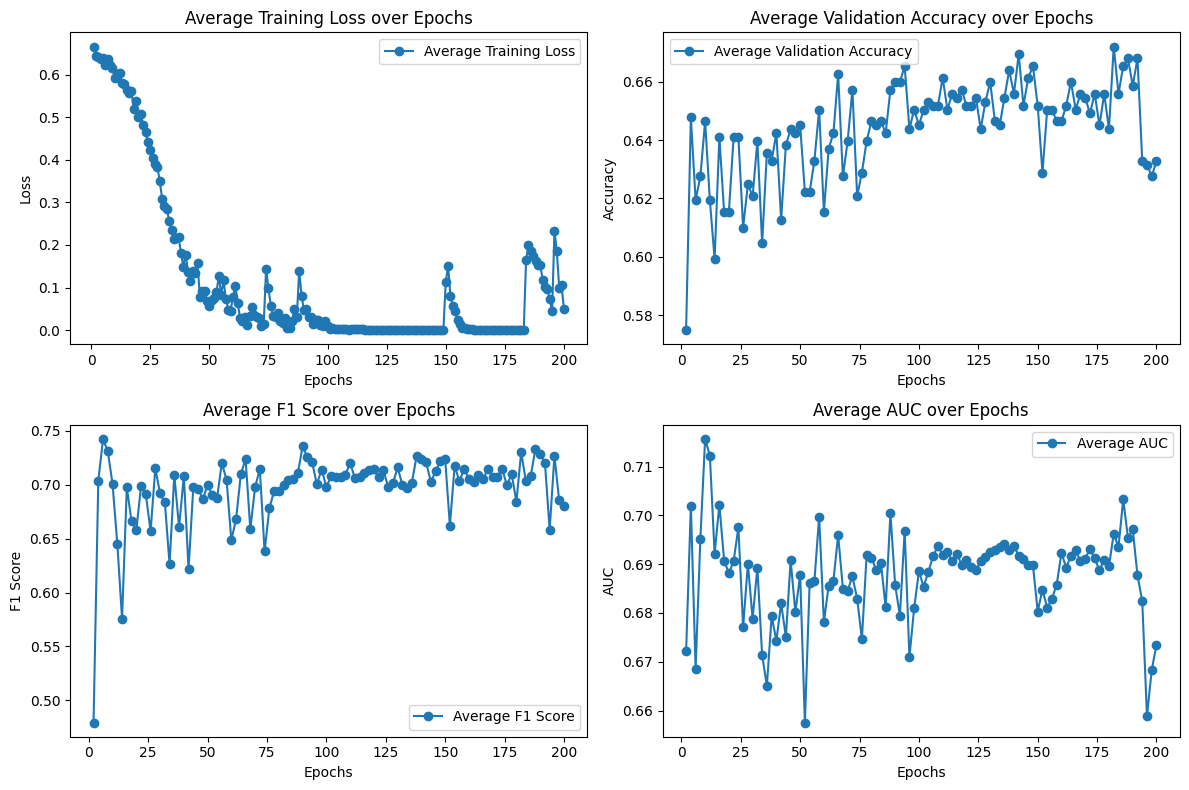

In [12]:
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 初始化 KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# 存储所有折的指标
all_epoch_loss_values = []
all_accuracy_values = []
all_sensitivity_values = []
all_specificity_values = []
all_f1_score_values = []
all_mcc_values = []
all_auc_values = []

# 获取所有样本
all_samples=positive_samples+negative_samples

# 开始三折交叉验证
for fold_idx, (train_indices, val_indices) in enumerate(kf.split(all_samples)):
    print(f"Starting Fold {fold_idx + 1}/3")
    
    # 初始化模型、损失函数和优化器
    model = monai.networks.nets.DenseNet121(spatial_dims=3, in_channels=3, out_channels=2).to(device)
    loss_function = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # 初始化存储当前折的训练损失和验证指标
    epoch_loss_values = []
    accuracy_values = []
    sensitivity_values = []
    specificity_values = []
    f1_score_values = []
    mcc_values = []
    auc_values = []

    best_metric = -1
    best_metric_epoch = -1

    # 开始训练
    max_epochs = 200
    val_interval = 2
    for epoch in range(max_epochs):
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1}/{max_epochs}")
        model.train()
        epoch_loss = 0
        step = 0

        # 训练部分
        for batch_data in train_loader:
            step += 1
            mri_images = batch_data["mri"].to(device)
            pet_1_images = batch_data["fdg"].to(device)
            pet_2_images = batch_data["av45"].to(device)
            labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)
            combined = torch.cat((mri_images, pet_1_images,pet_2_images), dim=1)

            if labels.dim() == 2:  # 转换 one-hot 编码标签为类索引
                labels = torch.argmax(labels, dim=1)

            optimizer.zero_grad()
            outputs = model(combined)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # 计算并保存平均训练损失
        epoch_loss /= step
        epoch_loss_values.append(epoch_loss)
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1} average loss: {epoch_loss:.4f}")

        # 验证部分每隔 val_interval 进行一次
        if (epoch + 1) % val_interval == 0:
            model.eval()
            y_true = []
            y_pred = []
            y_prob = []

            for val_data in val_loader:
                val_mri_images = val_data["mri"].to(device)
                val_pet_1_images = val_data["fdg"].to(device)
                val_pet_2_images = val_data["av45"].to(device)
                val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)
                val_combined = torch.cat((val_mri_images, val_pet_1_images,val_pet_2_images), dim=1)
                if val_labels.dim() == 2:
                    val_labels = torch.argmax(val_labels, dim=1)

                with torch.no_grad():
                    val_outputs = model(val_combined)
                    preds = val_outputs.argmax(dim=1)
                    y_true.extend(val_labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(val_outputs[:, 1].cpu().numpy())  # 概率用于 AUC 计算

            # 计算混淆矩阵和各项指标
            cm = confusion_matrix(y_true, y_pred)
            TN, FP, FN, TP = cm.ravel()  # 从混淆矩阵中提取 TN, FP, FN, TP

            acc = (TP + TN) / (TP + TN + FP + FN)  # 准确率
            sen = TP / (TP + FN)  # 敏感性
            spe = TN / (TN + FP)  # 特异性
            f1 = f1_score(y_true, y_pred)  # F1 分数
            mcc = matthews_corrcoef(y_true, y_pred)  # MCC
            auc = roc_auc_score(y_true, y_prob)  # AUC

            # 保存每个指标的值
            accuracy_values.append(acc)
            sensitivity_values.append(sen)
            specificity_values.append(spe)
            f1_score_values.append(f1)
            mcc_values.append(mcc)
            auc_values.append(auc)

            print(f"Fold {fold_idx + 1}, ACC: {acc:.4f}, SEN: {sen:.4f}, SPE: {spe:.4f}, F1: {f1:.4f}, MCC: {mcc:.4f}, AUC: {auc:.4f}")

            # 保存模型
            if acc > best_metric:
                best_metric = acc
                best_metric_epoch = epoch + 1
                torch.save(model.state_dict(), f"best_model_fold_{fold_idx + 1}.pth")
                print(f"Fold {fold_idx + 1}: saved new best metric model")

    # 保存当前折的指标
    all_epoch_loss_values.append(epoch_loss_values)
    all_accuracy_values.append(accuracy_values)
    all_sensitivity_values.append(sensitivity_values)
    all_specificity_values.append(specificity_values)
    all_f1_score_values.append(f1_score_values)
    all_mcc_values.append(mcc_values)
    all_auc_values.append(auc_values)

    print(f"Fold {fold_idx + 1} completed.")

# 打印所有折的平均指标
print("Cross-validation completed. Calculating average metrics...")

mean_accuracy = np.mean([np.mean(acc) for acc in all_accuracy_values])
mean_sensitivity = np.mean([np.mean(sen) for sen in all_sensitivity_values])
mean_specificity = np.mean([np.mean(spe) for spe in all_specificity_values])
mean_f1 = np.mean([np.mean(f1) for f1 in all_f1_score_values])
mean_mcc = np.mean([np.mean(mcc) for mcc in all_mcc_values])
mean_auc = np.mean([np.mean(auc) for auc in all_auc_values])

print(f"Average Accuracy: {mean_accuracy:.4f}")
print(f"Average Sensitivity: {mean_sensitivity:.4f}")
print(f"Average Specificity: {mean_specificity:.4f}")
print(f"Average F1 Score: {mean_f1:.4f}")
print(f"Average MCC: {mean_mcc:.4f}")
print(f"Average AUC: {mean_auc:.4f}")

# 绘制平均训练损失和验证指标曲线
epochs = range(1, len(all_epoch_loss_values[0]) + 1)
val_epochs = range(val_interval, max_epochs + 1, val_interval)

plt.figure(figsize=(12, 8))

# 平均训练损失曲线
plt.subplot(2, 2, 1)
mean_train_loss = np.mean(all_epoch_loss_values, axis=0)
plt.plot(epochs, mean_train_loss, label='Average Training Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Average Training Loss over Epochs')
plt.legend()

# 平均验证准确率曲线
plt.subplot(2, 2, 2)
mean_val_acc = np.mean(all_accuracy_values, axis=0)
plt.plot(val_epochs, mean_val_acc, label='Average Validation Accuracy', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Average Validation Accuracy over Epochs')
plt.legend()

# 平均 F1 Score 曲线
plt.subplot(2, 2, 3)
mean_val_f1 = np.mean(all_f1_score_values, axis=0)
plt.plot(val_epochs, mean_val_f1, label='Average F1 Score', marker='o')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('Average F1 Score over Epochs')
plt.legend()

# 平均 AUC 曲线
plt.subplot(2, 2, 4)
mean_val_auc = np.mean(all_auc_values, axis=0)
plt.plot(val_epochs, mean_val_auc, label='Average AUC', marker='o')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.title('Average AUC over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# mri concat av45 pet判断mci cn

Starting Fold 1/3
Fold 1, Epoch 1/200


/tmp/ipykernel_2910529/322001552.py:58: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 1, Epoch 1 average loss: 0.6562
Fold 1, Epoch 2/200
Fold 1, Epoch 2 average loss: 0.6305


/tmp/ipykernel_2910529/322001552.py:86: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 1: saved new best metric model at epoch 2
Fold 1, ACC: 0.6640, SEN: 0.8276, SPE: 0.4314, F1: 0.7430, MCC: 0.2842, AUC: 0.6657, Metric Sum: 1.3297
Fold 1, Epoch 3/200


...

Fold 3, ACC: 0.6397, SEN: 0.7172, SPE: 0.5294, F1: 0.7003, MCC: 0.2496, AUC: 0.7055, Metric Sum: 1.3452
Fold 3, Epoch 199/200


/tmp/ipykernel_2910529/322001552.py:58: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 3, Epoch 199 average loss: 0.0001
Fold 3, Epoch 200/200
Fold 3, Epoch 200 average loss: 0.0001


/tmp/ipykernel_2910529/322001552.py:86: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 3, ACC: 0.6316, SEN: 0.7034, SPE: 0.5294, F1: 0.6915, MCC: 0.2348, AUC: 0.7082, Metric Sum: 1.3398
Fold 3 completed. Best Metric Sum: 1.4337 at epoch 42
Cross-validation completed. Calculating average metrics...
Average Accuracy: 0.6540
Average Sensitivity: 0.7123
Average Specificity: 0.5710
Average F1 Score: 0.7001
Average MCC: 0.2906
Average AUC: 0.7152


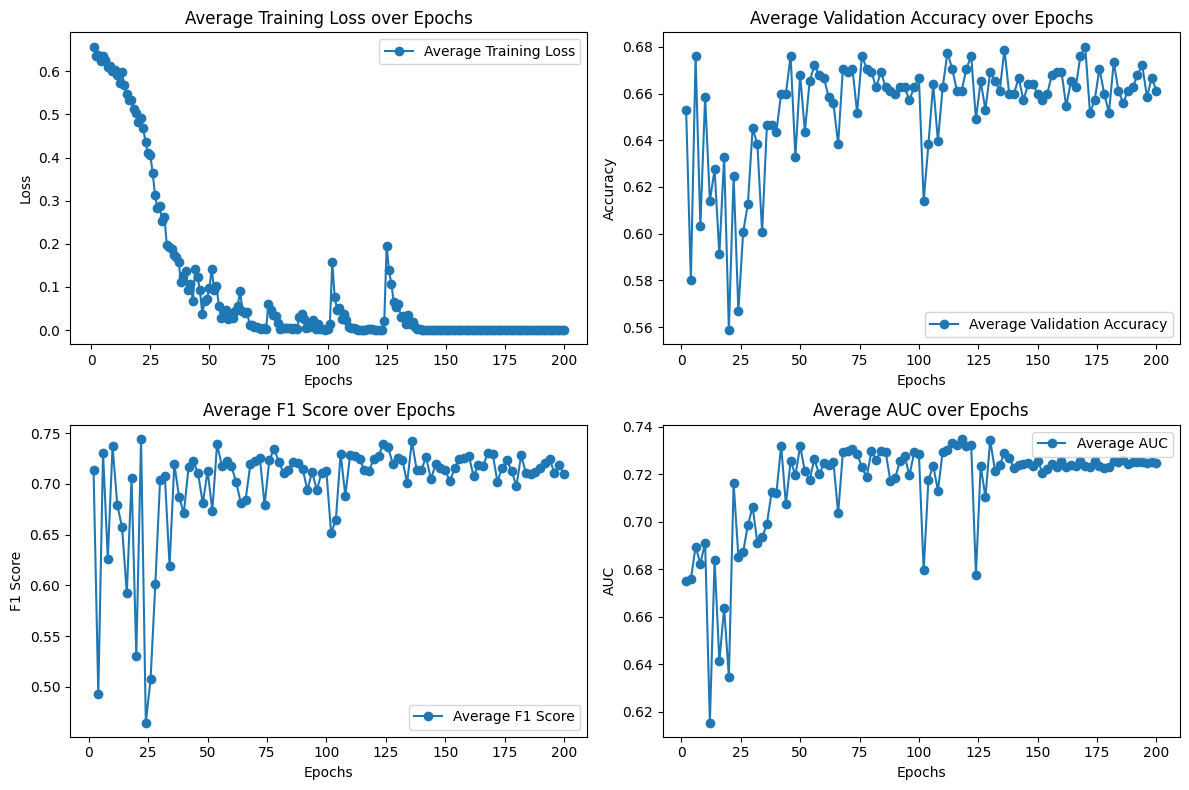

In [12]:
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 初始化 KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# 存储所有折的指标
all_epoch_loss_values = []
all_accuracy_values = []
all_sensitivity_values = []
all_specificity_values = []
all_f1_score_values = []
all_mcc_values = []
all_auc_values = []

# 获取所有样本
all_samples = positive_samples + negative_samples

# 开始三折交叉验证
for fold_idx, (train_indices, val_indices) in enumerate(kf.split(all_samples)):
    print(f"Starting Fold {fold_idx + 1}/3")
    
    # 初始化模型、损失函数和优化器
    model = monai.networks.nets.DenseNet121(spatial_dims=3, in_channels=2, out_channels=2).to(device)
    loss_function = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # 初始化存储当前折的训练损失和验证指标
    epoch_loss_values = []
    accuracy_values = []
    sensitivity_values = []
    specificity_values = []
    f1_score_values = []
    mcc_values = []
    auc_values = []

    best_metric_sum = -1  # 记录 AUC + ACC 的最大值
    best_metric_epoch = -1
    best_metrics = {}  # 记录最佳模型的各项指标

    # 开始训练
    max_epochs = 200
    val_interval = 2
    for epoch in range(max_epochs):
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1}/{max_epochs}")
        model.train()
        epoch_loss = 0
        step = 0

        # 训练部分
        for batch_data in train_loader:
            step += 1
            mri_images = batch_data["mri"].to(device)
            pet_images = batch_data["av45"].to(device)
            labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)
            combined = torch.cat((mri_images, pet_images), dim=1)

            if labels.dim() == 2:  # 转换 one-hot 编码标签为类索引
                labels = torch.argmax(labels, dim=1)

            optimizer.zero_grad()
            outputs = model(combined)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # 计算并保存平均训练损失
        epoch_loss /= step
        epoch_loss_values.append(epoch_loss)
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1} average loss: {epoch_loss:.4f}")

        # 验证部分每隔 val_interval 进行一次
        if (epoch + 1) % val_interval == 0:
            model.eval()
            y_true = []
            y_pred = []
            y_prob = []

            for val_data in val_loader:
                val_mri_images = val_data["mri"].to(device)
                val_pet_images = val_data["av45"].to(device)
                val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)
                val_combined = torch.cat((val_mri_images, val_pet_images), dim=1)
                if val_labels.dim() == 2:
                    val_labels = torch.argmax(val_labels, dim=1)

                with torch.no_grad():
                    val_outputs = model(val_combined)
                    preds = val_outputs.argmax(dim=1)
                    y_true.extend(val_labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(val_outputs[:, 1].cpu().numpy())  # 概率用于 AUC 计算

            # 计算混淆矩阵和各项指标
            cm = confusion_matrix(y_true, y_pred)
            TN, FP, FN, TP = cm.ravel()  # 从混淆矩阵中提取 TN, FP, FN, TP

            acc = (TP + TN) / (TP + TN + FP + FN)  # 准确率
            sen = TP / (TP + FN)  # 敏感性
            spe = TN / (TN + FP)  # 特异性
            f1 = f1_score(y_true, y_pred)  # F1 分数
            mcc = matthews_corrcoef(y_true, y_pred)  # MCC
            auc = roc_auc_score(y_true, y_prob)  # AUC

            # 计算 AUC + ACC 的总和
            metric_sum = auc + acc

            # 如果发现新的最大值，则更新最佳模型的指标和 epoch
            if metric_sum > best_metric_sum:
                best_metric_sum = metric_sum
                best_metric_epoch = epoch + 1
                best_metrics = {
                    "ACC": acc,
                    "SEN": sen,
                    "SPE": spe,
                    "F1": f1,
                    "MCC": mcc,
                    "AUC": auc,
                }
                torch.save(model.state_dict(), f"best_model_fold_{fold_idx + 1}.pth")
                print(f"Fold {fold_idx + 1}: saved new best metric model at epoch {best_metric_epoch}")

            # 保存每个指标的值
            accuracy_values.append(acc)
            sensitivity_values.append(sen)
            specificity_values.append(spe)
            f1_score_values.append(f1)
            mcc_values.append(mcc)
            auc_values.append(auc)

            print(f"Fold {fold_idx + 1}, ACC: {acc:.4f}, SEN: {sen:.4f}, SPE: {spe:.4f}, F1: {f1:.4f}, MCC: {mcc:.4f}, AUC: {auc:.4f}, Metric Sum: {metric_sum:.4f}")

    # 保存当前折的指标
    all_epoch_loss_values.append(epoch_loss_values)
    all_accuracy_values.append(accuracy_values)
    all_sensitivity_values.append(sensitivity_values)
    all_specificity_values.append(specificity_values)
    all_f1_score_values.append(f1_score_values)
    all_mcc_values.append(mcc_values)
    all_auc_values.append(auc_values)

    print(f"Fold {fold_idx + 1} completed. Best Metric Sum: {best_metric_sum:.4f} at epoch {best_metric_epoch}")

# 打印所有折的平均指标
print("Cross-validation completed. Calculating average metrics...")

mean_accuracy = np.mean([np.mean(acc) for acc in all_accuracy_values])
mean_sensitivity = np.mean([np.mean(sen) for sen in all_sensitivity_values])
mean_specificity = np.mean([np.mean(spe) for spe in all_specificity_values])
mean_f1 = np.mean([np.mean(f1) for f1 in all_f1_score_values])
mean_mcc = np.mean([np.mean(mcc) for mcc in all_mcc_values])
mean_auc = np.mean([np.mean(auc) for auc in all_auc_values])

print(f"Average Accuracy: {mean_accuracy:.4f}")
print(f"Average Sensitivity: {mean_sensitivity:.4f}")
print(f"Average Specificity: {mean_specificity:.4f}")
print(f"Average F1 Score: {mean_f1:.4f}")
print(f"Average MCC: {mean_mcc:.4f}")
print(f"Average AUC: {mean_auc:.4f}")

# 绘制平均训练损失和验证指标曲线
epochs = range(1, len(all_epoch_loss_values[0]) + 1)
val_epochs = range(val_interval, max_epochs + 1, val_interval)

plt.figure(figsize=(12, 8))

# 平均训练损失曲线
plt.subplot(2, 2, 1)
mean_train_loss = np.mean(all_epoch_loss_values, axis=0)
plt.plot(epochs, mean_train_loss, label='Average Training Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Average Training Loss over Epochs')
plt.legend()

# 平均验证准确率曲线
plt.subplot(2, 2, 2)
mean_val_acc = np.mean(all_accuracy_values, axis=0)
plt.plot(val_epochs, mean_val_acc, label='Average Validation Accuracy', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Average Validation Accuracy over Epochs')
plt.legend()

# 平均 F1 Score 曲线
plt.subplot(2, 2, 3)
mean_val_f1 = np.mean(all_f1_score_values, axis=0)
plt.plot(val_epochs, mean_val_f1, label='Average F1 Score', marker='o')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('Average F1 Score over Epochs')
plt.legend()

# 平均 AUC 曲线
plt.subplot(2, 2, 4)
mean_val_auc = np.mean(all_auc_values, axis=0)
plt.plot(val_epochs, mean_val_auc, label='Average AUC', marker='o')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.title('Average AUC over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# av45 pet 判断mci cn

Starting Fold 1/3
Fold 1, Epoch 1/200


/tmp/ipykernel_2910529/41702728.py:57: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 1, Epoch 1 average loss: 0.6677
Fold 1, Epoch 2/200
Fold 1, Epoch 2 average loss: 0.6519


/tmp/ipykernel_2910529/41702728.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 1: saved new best metric model at epoch 2
Fold 1, ACC: 0.5870, SEN: 1.0000, SPE: 0.0000, F1: 0.7398, MCC: 0.0000, AUC: 0.6161, Metric Sum: 1.2031
Fold 1, Epoch 3/200


...

Fold 3, ACC: 0.6478, SEN: 0.6552, SPE: 0.6373, F1: 0.6859, MCC: 0.2886, AUC: 0.6778, Metric Sum: 1.3255
Fold 3, Epoch 199/200


/tmp/ipykernel_2910529/41702728.py:57: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 3, Epoch 199 average loss: 0.0001
Fold 3, Epoch 200/200
Fold 3, Epoch 200 average loss: 0.0001


/tmp/ipykernel_2910529/41702728.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 3, ACC: 0.6397, SEN: 0.6345, SPE: 0.6471, F1: 0.6740, MCC: 0.2774, AUC: 0.6753, Metric Sum: 1.3149
Fold 3 completed. Best Metric Sum: 1.3641 at epoch 128
Cross-validation completed. Calculating average metrics...
Average Accuracy: 0.6101
Average Sensitivity: 0.6325
Average Specificity: 0.5783
Average F1 Score: 0.6478
Average MCC: 0.2154
Average AUC: 0.6593


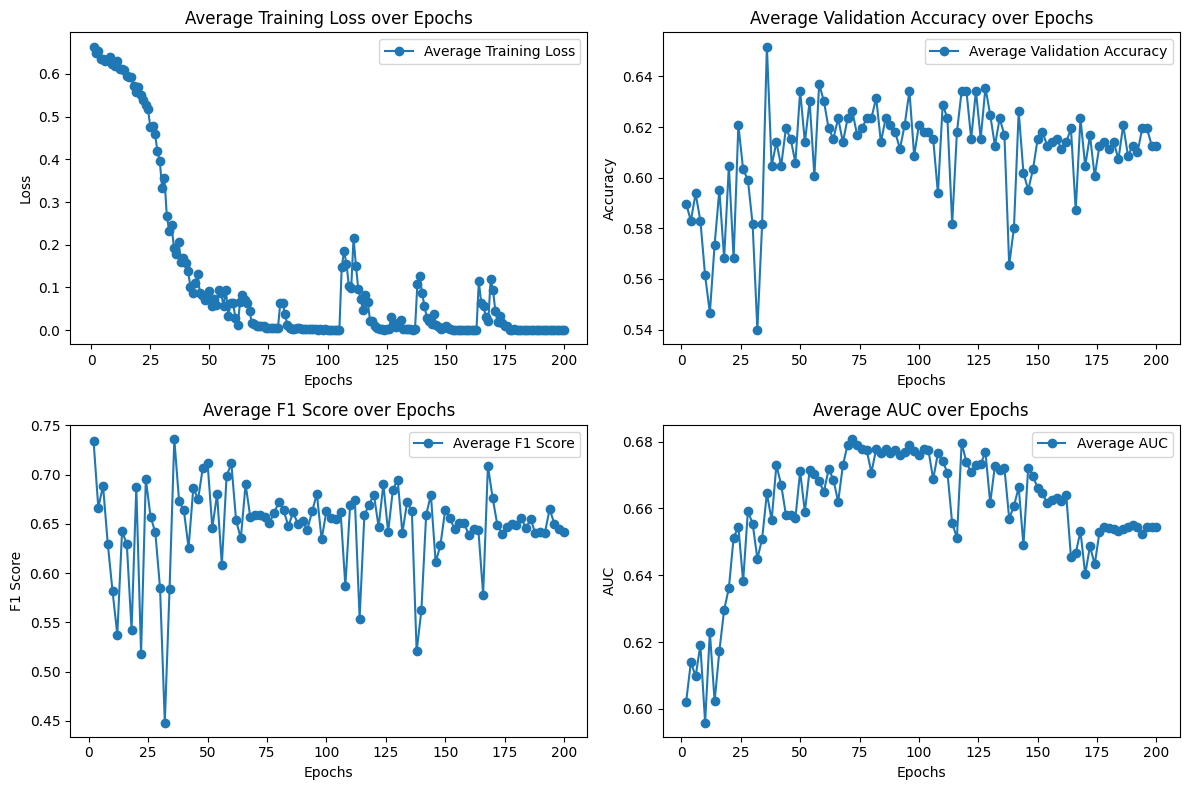

In [13]:
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 初始化 KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# 存储所有折的指标
all_epoch_loss_values = []
all_accuracy_values = []
all_sensitivity_values = []
all_specificity_values = []
all_f1_score_values = []
all_mcc_values = []
all_auc_values = []

# 获取所有样本
all_samples = positive_samples + negative_samples

# 开始三折交叉验证
for fold_idx, (train_indices, val_indices) in enumerate(kf.split(all_samples)):
    print(f"Starting Fold {fold_idx + 1}/3")
    
    # 初始化模型、损失函数和优化器
    model = monai.networks.nets.DenseNet121(spatial_dims=3, in_channels=1, out_channels=2).to(device)
    loss_function = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # 初始化存储当前折的训练损失和验证指标
    epoch_loss_values = []
    accuracy_values = []
    sensitivity_values = []
    specificity_values = []
    f1_score_values = []
    mcc_values = []
    auc_values = []

    best_metric_sum = -1  # 记录 AUC + ACC 的最大值
    best_metric_epoch = -1
    best_metrics = {}  # 记录最佳模型的各项指标

    # 开始训练
    max_epochs = 200
    val_interval = 2
    for epoch in range(max_epochs):
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1}/{max_epochs}")
        model.train()
        epoch_loss = 0
        step = 0

        # 训练部分
        for batch_data in train_loader:
            step += 1
            pet_images = batch_data["av45"].to(device)
            labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)

            if labels.dim() == 2:  # 转换 one-hot 编码标签为类索引
                labels = torch.argmax(labels, dim=1)

            optimizer.zero_grad()
            outputs = model(pet_images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # 计算并保存平均训练损失
        epoch_loss /= step
        epoch_loss_values.append(epoch_loss)
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1} average loss: {epoch_loss:.4f}")

        # 验证部分每隔 val_interval 进行一次
        if (epoch + 1) % val_interval == 0:
            model.eval()
            y_true = []
            y_pred = []
            y_prob = []

            for val_data in val_loader:
                val_pet_images = val_data["av45"].to(device)
                val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)
                if val_labels.dim() == 2:
                    val_labels = torch.argmax(val_labels, dim=1)

                with torch.no_grad():
                    val_outputs = model(val_pet_images)
                    preds = val_outputs.argmax(dim=1)
                    y_true.extend(val_labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(val_outputs[:, 1].cpu().numpy())  # 概率用于 AUC 计算

            # 计算混淆矩阵和各项指标
            cm = confusion_matrix(y_true, y_pred)
            TN, FP, FN, TP = cm.ravel()  # 从混淆矩阵中提取 TN, FP, FN, TP

            acc = (TP + TN) / (TP + TN + FP + FN)  # 准确率
            sen = TP / (TP + FN)  # 敏感性
            spe = TN / (TN + FP)  # 特异性
            f1 = f1_score(y_true, y_pred)  # F1 分数
            mcc = matthews_corrcoef(y_true, y_pred)  # MCC
            auc = roc_auc_score(y_true, y_prob)  # AUC

            # 计算 AUC + ACC 的总和
            metric_sum = auc + acc

            # 如果发现新的最大值，则更新最佳模型的指标和 epoch
            if metric_sum > best_metric_sum:
                best_metric_sum = metric_sum
                best_metric_epoch = epoch + 1
                best_metrics = {
                    "ACC": acc,
                    "SEN": sen,
                    "SPE": spe,
                    "F1": f1,
                    "MCC": mcc,
                    "AUC": auc,
                }
                torch.save(model.state_dict(), f"best_model_fold_{fold_idx + 1}.pth")
                print(f"Fold {fold_idx + 1}: saved new best metric model at epoch {best_metric_epoch}")

            # 保存每个指标的值
            accuracy_values.append(acc)
            sensitivity_values.append(sen)
            specificity_values.append(spe)
            f1_score_values.append(f1)
            mcc_values.append(mcc)
            auc_values.append(auc)

            print(f"Fold {fold_idx + 1}, ACC: {acc:.4f}, SEN: {sen:.4f}, SPE: {spe:.4f}, F1: {f1:.4f}, MCC: {mcc:.4f}, AUC: {auc:.4f}, Metric Sum: {metric_sum:.4f}")

    # 保存当前折的指标
    all_epoch_loss_values.append(epoch_loss_values)
    all_accuracy_values.append(accuracy_values)
    all_sensitivity_values.append(sensitivity_values)
    all_specificity_values.append(specificity_values)
    all_f1_score_values.append(f1_score_values)
    all_mcc_values.append(mcc_values)
    all_auc_values.append(auc_values)

    print(f"Fold {fold_idx + 1} completed. Best Metric Sum: {best_metric_sum:.4f} at epoch {best_metric_epoch}")

# 打印所有折的平均指标
print("Cross-validation completed. Calculating average metrics...")

mean_accuracy = np.mean([np.mean(acc) for acc in all_accuracy_values])
mean_sensitivity = np.mean([np.mean(sen) for sen in all_sensitivity_values])
mean_specificity = np.mean([np.mean(spe) for spe in all_specificity_values])
mean_f1 = np.mean([np.mean(f1) for f1 in all_f1_score_values])
mean_mcc = np.mean([np.mean(mcc) for mcc in all_mcc_values])
mean_auc = np.mean([np.mean(auc) for auc in all_auc_values])

print(f"Average Accuracy: {mean_accuracy:.4f}")
print(f"Average Sensitivity: {mean_sensitivity:.4f}")
print(f"Average Specificity: {mean_specificity:.4f}")
print(f"Average F1 Score: {mean_f1:.4f}")
print(f"Average MCC: {mean_mcc:.4f}")
print(f"Average AUC: {mean_auc:.4f}")

# 绘制平均训练损失和验证指标曲线
epochs = range(1, len(all_epoch_loss_values[0]) + 1)
val_epochs = range(val_interval, max_epochs + 1, val_interval)

plt.figure(figsize=(12, 8))

# 平均训练损失曲线
plt.subplot(2, 2, 1)
mean_train_loss = np.mean(all_epoch_loss_values, axis=0)
plt.plot(epochs, mean_train_loss, label='Average Training Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Average Training Loss over Epochs')
plt.legend()

# 平均验证准确率曲线
plt.subplot(2, 2, 2)
mean_val_acc = np.mean(all_accuracy_values, axis=0)
plt.plot(val_epochs, mean_val_acc, label='Average Validation Accuracy', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Average Validation Accuracy over Epochs')
plt.legend()

# 平均 F1 Score 曲线
plt.subplot(2, 2, 3)
mean_val_f1 = np.mean(all_f1_score_values, axis=0)
plt.plot(val_epochs, mean_val_f1, label='Average F1 Score', marker='o')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('Average F1 Score over Epochs')
plt.legend()

# 平均 AUC 曲线
plt.subplot(2, 2, 4)
mean_val_auc = np.mean(all_auc_values, axis=0)
plt.plot(val_epochs, mean_val_auc, label='Average AUC', marker='o')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.title('Average AUC over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

mri concat av45 pet concat fdg pet判断mci cn

Starting Fold 1/3
Fold 1, Epoch 1/200


/tmp/ipykernel_2910529/3055499794.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 1, Epoch 1 average loss: 0.6607
Fold 1, Epoch 2/200
Fold 1, Epoch 2 average loss: 0.6401


/tmp/ipykernel_2910529/3055499794.py:88: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 1: saved new best metric model at epoch 2
Fold 1, ACC: 0.6356, SEN: 0.6414, SPE: 0.6275, F1: 0.6739, MCC: 0.2652, AUC: 0.6708, Metric Sum: 1.3064
Fold 1, Epoch 3/200


...

Fold 3, ACC: 0.6640, SEN: 0.7310, SPE: 0.5686, F1: 0.7186, MCC: 0.3021, AUC: 0.7215, Metric Sum: 1.3855
Fold 3, Epoch 199/200


/tmp/ipykernel_2910529/3055499794.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)


Fold 3, Epoch 199 average loss: 0.0001
Fold 3, Epoch 200/200
Fold 3, Epoch 200 average loss: 0.0002


/tmp/ipykernel_2910529/3055499794.py:88: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)


Fold 3, ACC: 0.6559, SEN: 0.7172, SPE: 0.5686, F1: 0.7099, MCC: 0.2872, AUC: 0.7225, Metric Sum: 1.3784
Fold 3 completed. Best Metric Sum: 1.4546 at epoch 14
Cross-validation completed. Calculating average metrics...
Average Accuracy: 0.6653
Average Sensitivity: 0.7212
Average Specificity: 0.5858
Average F1 Score: 0.7125
Average MCC: 0.3153
Average AUC: 0.7141


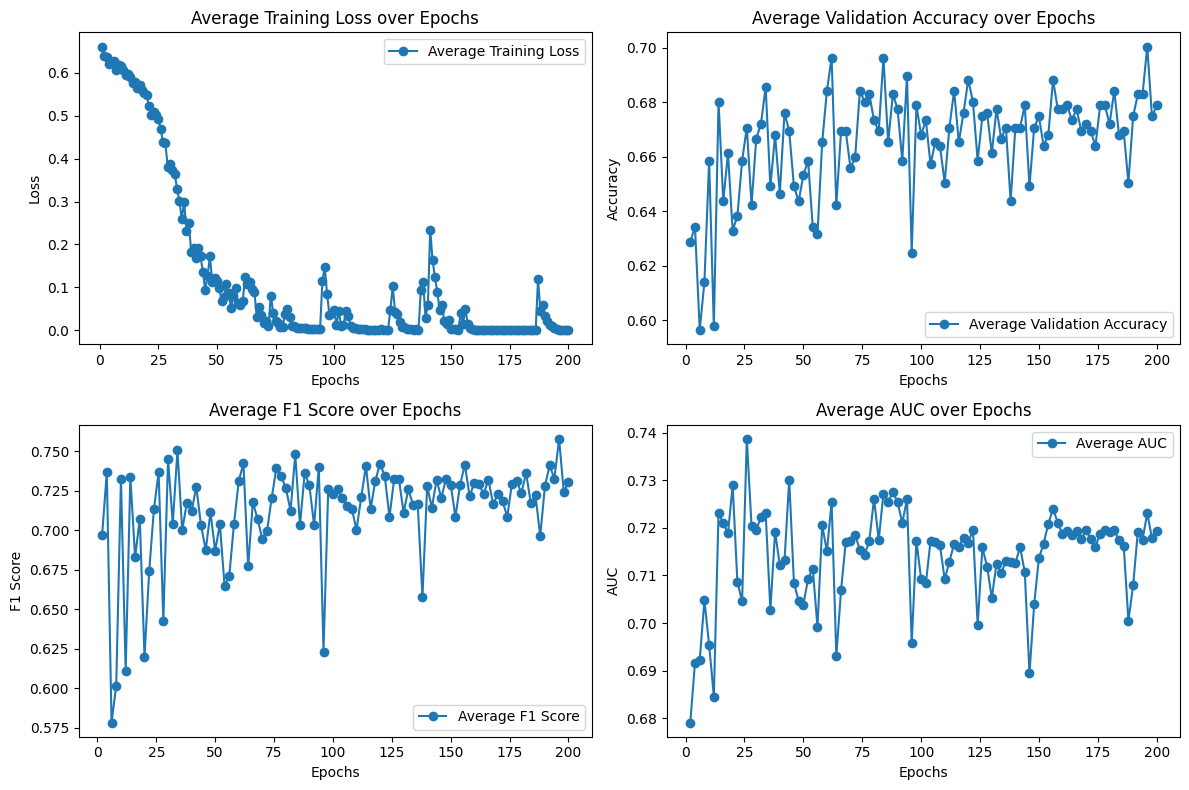

In [14]:
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 初始化 KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# 存储所有折的指标
all_epoch_loss_values = []
all_accuracy_values = []
all_sensitivity_values = []
all_specificity_values = []
all_f1_score_values = []
all_mcc_values = []
all_auc_values = []

# 获取所有样本
all_samples = positive_samples + negative_samples

# 开始三折交叉验证
for fold_idx, (train_indices, val_indices) in enumerate(kf.split(all_samples)):
    print(f"Starting Fold {fold_idx + 1}/3")
    
    # 初始化模型、损失函数和优化器
    model = monai.networks.nets.DenseNet121(spatial_dims=3, in_channels=3, out_channels=2).to(device)
    loss_function = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # 初始化存储当前折的训练损失和验证指标
    epoch_loss_values = []
    accuracy_values = []
    sensitivity_values = []
    specificity_values = []
    f1_score_values = []
    mcc_values = []
    auc_values = []

    best_metric_sum = -1  # 记录 AUC + ACC 的最大值
    best_metric_epoch = -1
    best_metrics = {}  # 记录最佳模型的各项指标

    # 开始训练
    max_epochs = 200
    val_interval = 2
    for epoch in range(max_epochs):
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1}/{max_epochs}")
        model.train()
        epoch_loss = 0
        step = 0

        # 训练部分
        for batch_data in train_loader:
            step += 1
            mri_images = batch_data["mri"].to(device)
            pet_1_images = batch_data["fdg"].to(device)
            pet_2_images = batch_data["av45"].to(device)
            labels = torch.tensor(batch_data["label"], dtype=torch.long).to(device)
            combined = torch.cat((mri_images, pet_1_images, pet_2_images), dim=1)

            if labels.dim() == 2:  # 转换 one-hot 编码标签为类索引
                labels = torch.argmax(labels, dim=1)

            optimizer.zero_grad()
            outputs = model(combined)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # 计算并保存平均训练损失
        epoch_loss /= step
        epoch_loss_values.append(epoch_loss)
        print(f"Fold {fold_idx + 1}, Epoch {epoch + 1} average loss: {epoch_loss:.4f}")

        # 验证部分每隔 val_interval 进行一次
        if (epoch + 1) % val_interval == 0:
            model.eval()
            y_true = []
            y_pred = []
            y_prob = []

            for val_data in val_loader:
                val_mri_images = val_data["mri"].to(device)
                val_pet_1_images = val_data["fdg"].to(device)
                val_pet_2_images = val_data["av45"].to(device)
                val_labels = torch.tensor(val_data["label"], dtype=torch.long).to(device)
                val_combined = torch.cat((val_mri_images, val_pet_1_images, val_pet_2_images), dim=1)
                if val_labels.dim() == 2:
                    val_labels = torch.argmax(val_labels, dim=1)

                with torch.no_grad():
                    val_outputs = model(val_combined)
                    preds = val_outputs.argmax(dim=1)
                    y_true.extend(val_labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(val_outputs[:, 1].cpu().numpy())  # 概率用于 AUC 计算

            # 计算混淆矩阵和各项指标
            cm = confusion_matrix(y_true, y_pred)
            TN, FP, FN, TP = cm.ravel()  # 从混淆矩阵中提取 TN, FP, FN, TP

            acc = (TP + TN) / (TP + TN + FP + FN)  # 准确率
            sen = TP / (TP + FN)  # 敏感性
            spe = TN / (TN + FP)  # 特异性
            f1 = f1_score(y_true, y_pred)  # F1 分数
            mcc = matthews_corrcoef(y_true, y_pred)  # MCC
            auc = roc_auc_score(y_true, y_prob)  # AUC

            # 计算 AUC + ACC 的总和
            metric_sum = auc + acc

            # 如果发现新的最大值，则更新最佳模型的指标和 epoch
            if metric_sum > best_metric_sum:
                best_metric_sum = metric_sum
                best_metric_epoch = epoch + 1
                best_metrics = {
                    "ACC": acc,
                    "SEN": sen,
                    "SPE": spe,
                    "F1": f1,
                    "MCC": mcc,
                    "AUC": auc,
                }
                torch.save(model.state_dict(), f"best_model_fold_{fold_idx + 1}.pth")
                print(f"Fold {fold_idx + 1}: saved new best metric model at epoch {best_metric_epoch}")

            # 保存每个指标的值
            accuracy_values.append(acc)
            sensitivity_values.append(sen)
            specificity_values.append(spe)
            f1_score_values.append(f1)
            mcc_values.append(mcc)
            auc_values.append(auc)

            print(f"Fold {fold_idx + 1}, ACC: {acc:.4f}, SEN: {sen:.4f}, SPE: {spe:.4f}, F1: {f1:.4f}, MCC: {mcc:.4f}, AUC: {auc:.4f}, Metric Sum: {metric_sum:.4f}")

    # 保存当前折的指标
    all_epoch_loss_values.append(epoch_loss_values)
    all_accuracy_values.append(accuracy_values)
    all_sensitivity_values.append(sensitivity_values)
    all_specificity_values.append(specificity_values)
    all_f1_score_values.append(f1_score_values)
    all_mcc_values.append(mcc_values)
    all_auc_values.append(auc_values)

    print(f"Fold {fold_idx + 1} completed. Best Metric Sum: {best_metric_sum:.4f} at epoch {best_metric_epoch}")

# 打印所有折的平均指标
print("Cross-validation completed. Calculating average metrics...")

mean_accuracy = np.mean([np.mean(acc) for acc in all_accuracy_values])
mean_sensitivity = np.mean([np.mean(sen) for sen in all_sensitivity_values])
mean_specificity = np.mean([np.mean(spe) for spe in all_specificity_values])
mean_f1 = np.mean([np.mean(f1) for f1 in all_f1_score_values])
mean_mcc = np.mean([np.mean(mcc) for mcc in all_mcc_values])
mean_auc = np.mean([np.mean(auc) for auc in all_auc_values])

print(f"Average Accuracy: {mean_accuracy:.4f}")
print(f"Average Sensitivity: {mean_sensitivity:.4f}")
print(f"Average Specificity: {mean_specificity:.4f}")
print(f"Average F1 Score: {mean_f1:.4f}")
print(f"Average MCC: {mean_mcc:.4f}")
print(f"Average AUC: {mean_auc:.4f}")

# 绘制平均训练损失和验证指标曲线
epochs = range(1, len(all_epoch_loss_values[0]) + 1)
val_epochs = range(val_interval, max_epochs + 1, val_interval)

plt.figure(figsize=(12, 8))

# 平均训练损失曲线
plt.subplot(2, 2, 1)
mean_train_loss = np.mean(all_epoch_loss_values, axis=0)
plt.plot(epochs, mean_train_loss, label='Average Training Loss', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Average Training Loss over Epochs')
plt.legend()

# 平均验证准确率曲线
plt.subplot(2, 2, 2)
mean_val_acc = np.mean(all_accuracy_values, axis=0)
plt.plot(val_epochs, mean_val_acc, label='Average Validation Accuracy', marker='o')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Average Validation Accuracy over Epochs')
plt.legend()

# 平均 F1 Score 曲线
plt.subplot(2, 2, 3)
mean_val_f1 = np.mean(all_f1_score_values, axis=0)
plt.plot(val_epochs, mean_val_f1, label='Average F1 Score', marker='o')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('Average F1 Score over Epochs')
plt.legend()

# 平均 AUC 曲线
plt.subplot(2, 2, 4)
mean_val_auc = np.mean(all_auc_values, axis=0)
plt.plot(val_epochs, mean_val_auc, label='Average AUC', marker='o')
plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.title('Average AUC over Epochs')
plt.legend()

plt.tight_layout()
plt.show()